In [9]:
# conda env 'misr'

import MisrToolkit as mtk
import numpy as np
import matplotlib.pyplot as plt

# # These are some parameters to make figures nice (and big)
# params = {'legend.fontsize': 'x-large',
#          'axes.labelsize': 'x-large',
#          'axes.titlesize': 'x-large',
#          'xtick.labelsize': 'x-large',
#          'ytick.labelsize': 'x-large'}

# plt.rcParams.update(params)

In [10]:
def nearest_sample(lat, lon, path, resolution):
    region = mtk.MtkRegion(lat,lon, 1, 1, "km")
    lats, lons = region.snap_to_grid(path, resolution).create_latlon()
    lats = lats.ravel()
    lons = lons.ravel()
    lat_diff = lats - lat
    lon_diff = lons - lon
    D = (lat_diff**2 + lon_diff**2)**0.5
    return lats[np.argmin(D)], lons[np.argmin(D)]

In [11]:
database = '../../data/MISR'
tc_cloud_general = '{}/MISR_AM1_TC_CLOUD_P{:d}_O{:d}_F01_0001.hdf'
path = 117
orbit = 105254
lat, lon = nearest_sample(18.9223805, 120.0291074, path, 17600)
n = 17
region = mtk.MtkRegion(lat, lon, 8.8*n, 8.8*n, "km")
lat17600, lon17600 = region.snap_to_grid(path, 17600).create_latlon()
assert lat17600.shape[0] % 2 == 1
assert lon17600.shape[0] % 2 == 1
i_center_lat = int((lat17600.shape[0] - 1) / 2)
j_center_lon = int((lon17600.shape[1] - 1) / 2)

In [12]:
grp_general = '{}/MISR_AM1_GRP_ELLIPSOID_GM_P{:d}_O{:d}_{}_F03_0024.hdf'
nadir_file = grp_general.format(database, path, orbit, 'AN')
lat275, lon275 = region.snap_to_grid(path, 275).create_latlon()
brf = mtk.MtkFile(nadir_file).grid('RedBand').field('Red Brf').read(region).data()

In [14]:
tc_cloud_file = tc_cloud_general.format(database, path, orbit)
cmv_grid = mtk.MtkFile(tc_cloud_file).grid('Motion_17.6_km')
CTH = cmv_grid.field('CloudTopHeightOfMotion').read(region).data()
CTH[CTH == -9999] = 0
CMV_N = cmv_grid.field('CloudMotionNorthward').read(region).data()
CMV_N[CMV_N == -9999] = 0
CMV_E = cmv_grid.field('CloudMotionEastward').read(region).data()
CMV_E[CMV_E == -9999] = 0
CMV_Speed = (CMV_N**2 + CMV_E**2)**0.5

Text(0, 0.5, 'Latitude (deg)')

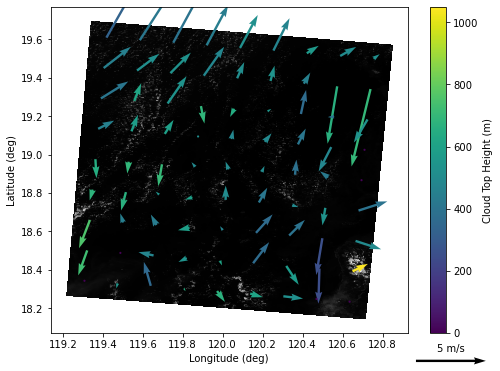

In [15]:
f, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.scatter(lon275, lat275, c=brf, marker='s', s=1, cmap='gray')
q = ax.quiver(lon17600, lat17600, CMV_E, CMV_N, CTH, units='xy')
ax.quiverkey(q, 0.82, 0.06, 5, '5 m/s', labelpos='N', coordinates='figure')
plt.colorbar(q, label='Cloud Top Height (m)')
ax.set_xlabel('Longitude (deg)')
ax.set_ylabel('Latitude (deg)')

Text(0, 0.5, 'Latitude (deg)')

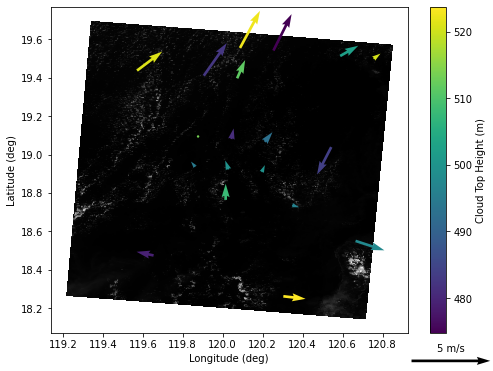

In [16]:
center_CTH = CTH[i_center_lat, j_center_lon]
half_bin = 25 # m
cond = (CTH > (center_CTH - half_bin)) & (CTH < (center_CTH + half_bin))
f, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.scatter(lon275, lat275, c=brf, marker='s', s=1, cmap='gray')
q = ax.quiver(lon17600[cond], lat17600[cond], CMV_E[cond], CMV_N[cond], CTH[cond], units='xy')
ax.quiverkey(q, 0.82, 0.06, 5, '5 m/s', labelpos='N', coordinates='figure')
plt.colorbar(q, label='Cloud Top Height (m)')
ax.set_xlabel('Longitude (deg)')
ax.set_ylabel('Latitude (deg)')

In [17]:
print('Center CTH: {:.0f} m'.format(CTH[i_center_lat, j_center_lon]))
print('Center CMV East: {:.2f} m/s'.format(CMV_E[i_center_lat, j_center_lon]))
print('Center CMV North: {:.2f} m/s'.format(CMV_N[i_center_lat, j_center_lon]))
print('Center CMV Speed: {:.2f} m/s'.format(CMV_Speed[i_center_lat, j_center_lon]))
print('Center CMV Direction: {:.0f} deg'.format(np.arctan2(CMV_E[i_center_lat, j_center_lon], CMV_N[i_center_lat, j_center_lon]) * 180 / np.pi))
print()
print('Average of n = {:d} CMVs between {:.0f} and {:.0f} m:'.format(np.sum(cond), center_CTH - half_bin, center_CTH + half_bin))
print('Average CMV East: {:.2f} m/s'.format(np.mean(CMV_E[cond])))
print('Average CMV North: {:.2f} m/s'.format(np.mean(CMV_N[cond])))
print('Average CMV Speed: {:.2f} m/s'.format((np.mean(CMV_E[cond])**2 + np.mean(CMV_N[cond])**2)**0.5))
print('Average CMV Direction: {:.0f} deg'.format(np.arctan2(np.mean(CMV_E[cond]), np.mean(CMV_N[cond])) * 180 / np.pi))
print()
print('Average CMV Speed: {:.2f} m/s'.format(np.mean(CMV_Speed[cond])))

Center CTH: 500 m
Center CMV East: -0.21 m/s
Center CMV North: 0.57 m/s
Center CMV Speed: 0.61 m/s
Center CMV Direction: -20 deg

Average of n = 19 CMVs between 475 and 525 m:
Average CMV East: 0.50 m/s
Average CMV North: 0.60 m/s
Average CMV Speed: 0.78 m/s
Average CMV Direction: 40 deg

Average CMV Speed: 1.26 m/s
